<a href="https://colab.research.google.com/github/Vincent-L0/A04-clustering/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Vincent Lam

**Date:** 10/14/26

(2)



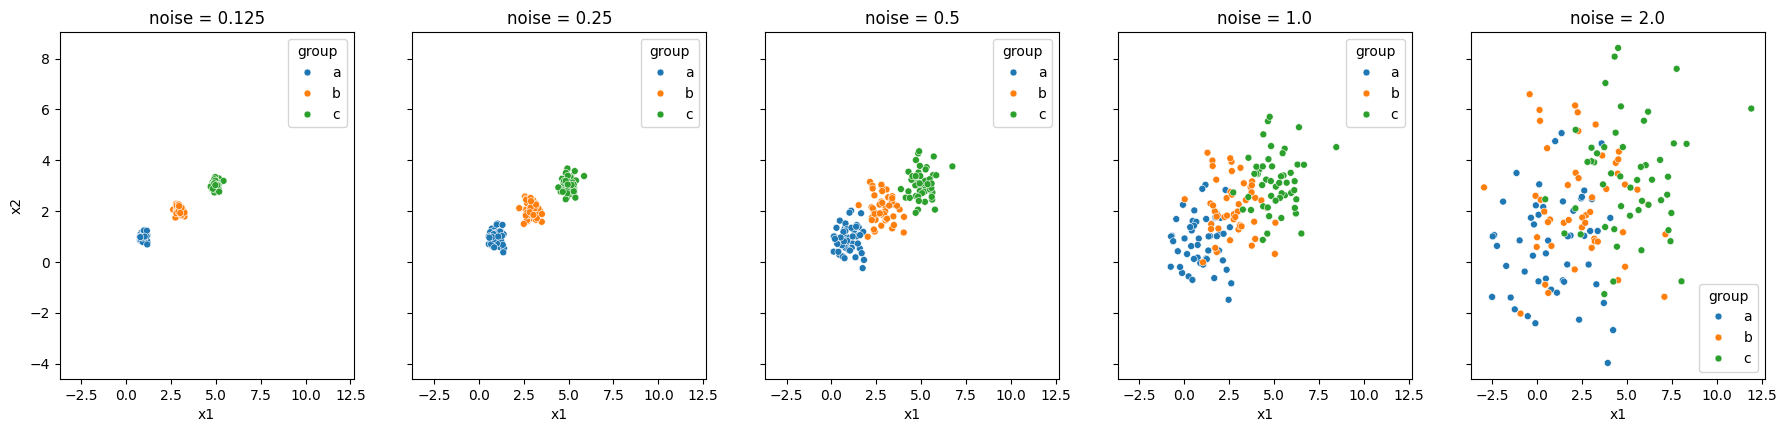

As noise increases, the clusters spread out from their centers. This causes them to overlap and become harder to distinguish. 
At a noise of 2.0 they look like one large cloud.

------------------------------------------------------------------------
(3)



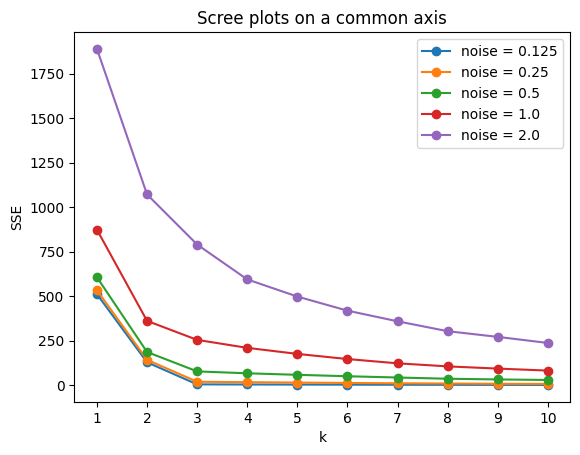

,0.125,0.250,0.500,1.000,2.000
1,511.6,533.3,606.6,873.7,1889.2
2,128.9,142.7,186.8,361.6,1071.8
3,4.9,19.7,77.8,254.9,790.5
4,4.3,17.3,67.2,210.1,594.5
5,3.8,15.1,58.7,176.1,498.2
6,3.3,12.9,50.6,147.2,419.0
7,2.8,11.2,43.5,123.2,359.3
8,2.5,9.7,36.6,106.1,303.7
9,2.2,8.2,32.7,93.6,271.7
10,1.9,7.5,29.7,82.4,237.6


As noise increases, the scree curve has a vertical shift upward, increasing SSE. This also results in a lower percentage of SSE 
being lost as k increases, making it more difficult to find the best k value, as seen by the elbow being less clear as noise increases.

------------------------------------------------------------------------
(4)

The elbow provides a clear point where someone can see that adding another cluster stops reducing SSE by much. 
In the low-noise data, SSE drops sharply at k = 3 because each center lands on a clear group, but a fourth cluster only splits a tight group 
and barely reduces SSE. With high noise the groups overlap, so no k gives a sudden drop and the elbow disappears.



In [ ]:
# Your Phase 1 solution to the problem goes here.
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans

#1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

print("(2)\n")

datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
for ax, (noise, d) in zip(axes, datasets.items()):
    sns.scatterplot(data=d, x="x1", y="x2", hue="group", s=25, ax=ax)
    ax.set_title(f"noise = {noise}")
plt.show()

print("""As noise increases, the clusters spread out from their centers. This causes them to overlap and become harder to distinguish.
At a noise of 2.0 they look like one large cloud.\n""")


print("------------------------------------------------------------------------")
print("(3)\n")

ks = np.arange(1, 11)

sse = {}
for noise, d in datasets.items():
    sse[noise] = []
    for k in ks:
        model = KMeans(n_clusters=k, n_init=10, random_state=100)
        fitted_model = model.fit(d[["x1", "x2"]])
        sse[noise].append(fitted_model.inertia_)
    plt.plot(ks, sse[noise], marker="o", label=f"noise = {noise}")
plt.xticks(ks)
plt.title("Scree plots on a common axis")
plt.xlabel("k")
plt.ylabel("SSE")
plt.legend()
plt.show()

display(pd.DataFrame(sse, index=ks).round(1))

print("""As noise increases, the scree curve has a vertical shift upward, increasing SSE. This also results in a lower percentage of SSE
being lost as k increases, making it more difficult to find the best k value, as seen by the elbow being less clear as noise increases.\n""")

print("------------------------------------------------------------------------")
print("(4)\n")

print("""The elbow provides a clear point where someone can see that adding another cluster stops reducing SSE by much.
In the low-noise data, SSE drops sharply at k = 3 because each center lands on a clear group, but a fourth cluster only splits a tight group
and barely reduces SSE. With high noise the groups overlap, so no k gives a sudden drop and the elbow disappears.\n""")

(Q2)

(1)

(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

Dropped: ['Costa Rica', "Cote d'Ivoire", 'Cuba', 'Czechoslovakia', 'Djibouti', 'Eritrea', 'Eswatini', 'German Democratic Republic', 'Iceland', 'Korea, North', 'Laos', 'Libya', 'Panama', 'Qatar', 'Somalia', 'Syria', 'Turkmenistan', 'United Arab Emirates', 'USSR', 'Uzbekistan', 'Venezuela', 'Viet Nam', 'Yemen', 'Yemen, North', 'Yugoslavia']


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
count,148.000000,148.000000,148.000000,148.000000
mean,13153.747670,268.264494,0.061510,0.019619
std,68005.236120,430.434878,0.046207,0.015033
min,8.622460,0.580129,0.004896,0.000054
25%,204.877177,20.553464,0.031352,0.010413
50%,959.535443,81.506703,0.047402,0.015324
75%,5289.998320,326.267753,0.084681,0.024327
max,778397.200000,2520.398541,0.303027,0.098470


Filtering to 2020 and dropping missing values leaves 148 countries. No further cleaning is needed since all four
 variables are already numeric, although the data is very skewed because the U.S.'s spending is far larger than any other country’s.

------------------------------------------------------------------------
(2)



,Spending (2020 USD),Spending per Capita
min,0.0,0.0
max,1.0,1.0


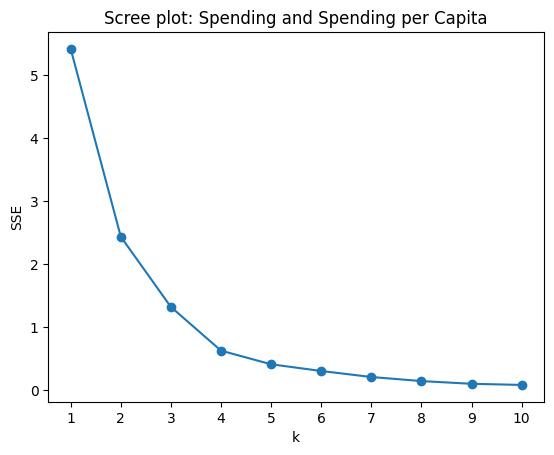

SSE: [5.411 2.435 1.322 0.629 0.413 0.307 0.212 0.147 0.104 0.086]


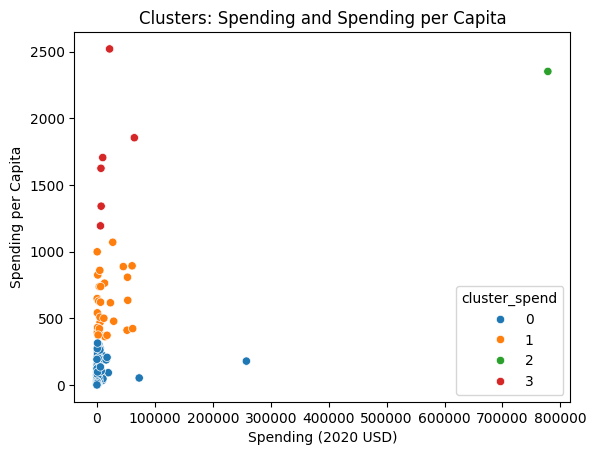

Cluster 0 (111 countries): China, India, Brazil, Turkey, Iran, Pakistan, Algeria, Colombia, Indonesia, Mexico, Thailand, Ukraine
Cluster 1 (30 countries): Russia, United Kingdom, Germany, France, Japan, Korea, South, Italy, Australia, Canada, Spain, Poland, Netherlands
Cluster 2 (1 countries): United States of America
Cluster 3 (6 countries): Saudi Arabia, Israel, Singapore, Norway, Kuwait, Oman

USA is in cluster 2


cluster_spend                          0             1              2  \
Spending (2020 USD) count     111.000000     30.000000       1.000000   
                    mean     4859.185065  17077.591354  778397.200000   
                    std     25405.739131  20583.053357            NaN   
                    min         8.622460    405.790494  778397.200000   
                    25%       130.010211   2294.039665  778397.200000   
                    50%       382.464677   5857.060906  778397.200000   
                    75%      2297.032353  26296.001003  778397.200000   
                    max    257973.429834  61712.537169  778397.200000   
Spending per Capita count     111.000000     30.000000       1.000000   
                    mean       80.061470    607.478618    2351.631858   
                    std        83.501824    206.928757            NaN   
                    min         0.580129    362.467076    2351.631858   
                    25%        14.880549    422.208252    2351.631858   
                    50%        47.056944    579.004604    2351.631858   
                    75%       125.387558    757.328513    2351.631858   
                    max       314.201312   1070.623322    2351.631858   

cluster_spend                         3  
Spending (2020 USD) count      6.000000  
                    mean   19443.362047  
                    std    22861.507114  
                    min     6095.708713  
                    25%     7023.251766  
                    50%     8624.225729  
                    75%    18857.070183  
                    max    64558.400000  
Spending per Capita count      6.000000  
                    mean    1706.721916  
                    std      466.375705  
                    min     1193.598730  
                    25%     1412.083201  
                    50%     1665.447478  
                    75%     1817.219993  
                    max     2520.398541

Using k = 4, the U.S. is in a cluster by itself because its total spending is so large that every other country
 is squeezed near 0 after min-max scaling. The remaining countries are grouped mainly by spending per capita, so China
  and India land in the low cluster with most of the world, while wealthy countries like Saudi Arabia and Israel form the higher clusters.

------------------------------------------------------------------------
(3)



,Percent of Government Spending,Percent of GDP
min,0.0,0.0
max,1.0,1.0


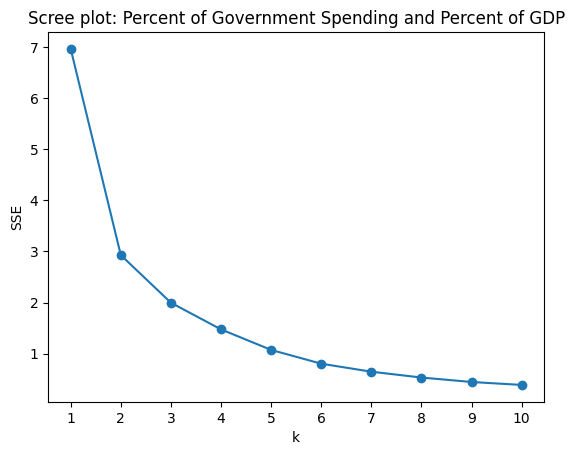

SSE: [6.961 2.927 1.996 1.474 1.073 0.803 0.646 0.532 0.445 0.388]


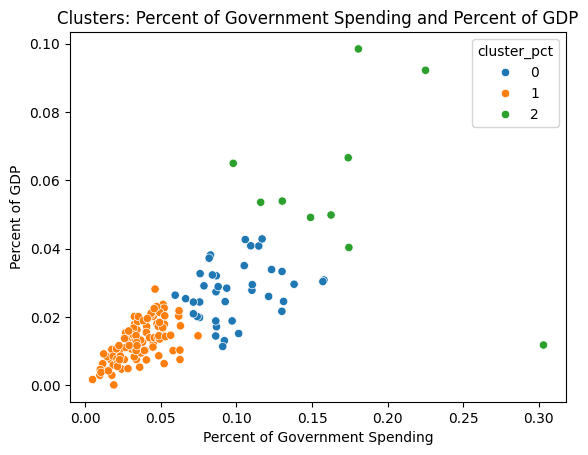

Cluster 0 (39 countries): United States of America, India, Russia, Korea, South, Turkey, Iran, Taiwan, Singapore, Colombia, Ukraine, Iraq, Chile
Cluster 1 (99 countries): China, United Kingdom, Germany, France, Japan, Italy, Australia, Canada, Brazil, Spain, Poland, Netherlands
Cluster 2 (10 countries): Saudi Arabia, Israel, Pakistan, Algeria, Kuwait, Oman, Azerbaijan, Jordan, Belarus, Armenia

USA is in cluster 0


cluster_pct                                   0          1          2
Percent of Government Spending count  39.000000  99.000000  10.000000
                               mean    0.098683   0.035777   0.171289
                               std     0.024125   0.014549   0.058725
                               min     0.059520   0.004896   0.097882
                               25%     0.082430   0.025921   0.135010
                               50%     0.092044   0.034261   0.168248
                               75%     0.112633   0.047402   0.179081
                               max     0.157918   0.074624   0.303027
Percent of GDP                 count  39.000000  99.000000  10.000000
                               mean    0.027412   0.012664   0.058071
                               std     0.008191   0.005681   0.024867
                               min     0.011317   0.000054   0.011742
                               25%     0.021254   0.008393   0.049297
                               50%     0.027781   0.013191   0.053729
                               75%     0.032461   0.016752   0.066190
                               max     0.042810   0.028132   0.098470

Using k = 3, the countries split into low, medium and high military burden, and the U.S. is in the middle group with Russia and India.
 Unlike part 2, which grouped countries by wealth and size, these clusters show how militarized a country is, with countries in conflict regions
  like Saudi Arabia, Israel and Pakistan in the high group.

------------------------------------------------------------------------
(4)



,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


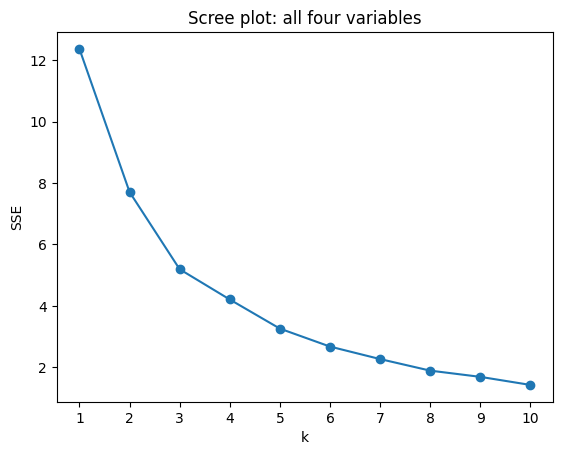

SSE: [12.372  7.71   5.193  4.207  3.258  2.673  2.265  1.889  1.686  1.423]
Cluster 0 (26 countries): United Kingdom, Germany, France, Japan, Italy, Australia, Canada, Spain, Poland, Netherlands, Norway, Switzerland
Cluster 1 (30 countries): India, Russia, Korea, South, Iran, Taiwan, Pakistan, Algeria, Colombia, Ukraine, Iraq, Morocco, Myanmar
Cluster 2 (86 countries): China, Brazil, Turkey, Indonesia, Mexico, Thailand, Chile, Romania, Bangladesh, Egypt, Philippines, Malaysia
Cluster 3 (6 countries): United States of America, Saudi Arabia, Israel, Singapore, Kuwait, Oman

USA is in cluster 3


cluster_spend,0,1,2,3
cluster_all,,,,
0,0,25,0,1
1,25,5,0,0
2,86,0,0,0
3,0,0,1,5


cluster_all                                      0             1  \
Spending (2020 USD)            count     26.000000     30.000000   
                               mean   15330.618681   9073.543709   
                               std    18923.469359  18135.032885   
                               min      405.790494    163.926877   
                               25%     3176.345598    522.737081   
                               50%     5857.060906   1663.090134   
                               75%    21818.934764   8646.648849   
                               max    60675.039625  72937.064048   
Spending per Capita            count     26.000000     30.000000   
                               mean     612.677541    215.920971   
                               std      241.189507    261.610456   
                               min      362.467076     18.297119   
                               25%      413.682029     46.200403   
                               50%      579.004604    137.955585   
                               75%      738.120108    219.021206   
                               max     1341.058851    998.966186   
Percent of Government Spending count     26.000000     30.000000   
                               mean       0.033280      0.123701   
                               std        0.011771      0.044494   
                               min        0.011613      0.076005   
                               25%        0.026028      0.092832   
                               50%        0.032077      0.115883   
                               75%        0.044645      0.136403   
                               max        0.052209      0.303027   
Percent of GDP                 count     26.000000     30.000000   
                               mean       0.016585      0.034105   
                               std        0.005525      0.011116   
                               min        0.006273      0.011742   
                               25%        0.013689      0.027933   
                               50%        0.015324      0.032148   
                               75%        0.020431      0.040637   
                               max        0.028132      0.066600   

cluster_all                                       2              3  
Spending (2020 USD)            count      86.000000       6.000000  
                               mean     4513.543790  147964.582042  
                               std     27841.230783  309635.189564  
                               min         8.622460    6095.708713  
                               25%        81.022976    7700.424616  
                               50%       288.061512   15897.570598  
                               75%      1138.618231   53872.942442  
                               max    257973.429834  778397.200000  
Spending per Capita            count      86.000000       6.000000  
                               mean       70.290644    1875.150751  
                               std        81.690590     489.800206  
                               min         0.580129    1193.598730  
                               25%        11.522275    1645.301864  
                               50%        34.845855    1780.059564  
                               75%        95.985387    2227.318999  
                               max       314.201312    2520.398541  
Percent of Government Spending count      86.000000       6.000000  
                               mean        0.043199       0.135351  
                               std         0.021512       0.055392  
                               min         0.004896       0.081976  
                               25%         0.028414       0.101034  
                               50%         0.040096       0.113271  
                               75%         0.053006       0.164503  
                               max         0.101501       0.225050  
Percent of GDP                

Using all four variables with k = 4 combines the previous two parts, separating countries by both wealth and military burden. The U.S. 
is no longer alone and is grouped with other rich, high-burden countries like Saudi Arabia and Israel, while part 2’s large low cluster splits 
into low- and high-burden groups.

------------------------------------------------------------------------
(5)

Partly. It showed that total spending and military burden are different, since rich European countries spend a lot but only a small share
 of their economy. However, the results depend heavily on normalization and the choice of k, and the U.S. outlier distorted the clusters in part 2.



In [ ]:
print("(Q2)\n")
print("(1)\n")
raw = pd.read_csv("/content/SIPRI Military Expenditure Database.csv")
df_2020 = raw.loc[raw["Year"] == 2020]
df = df_2020.dropna().copy()

num_vars = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
print(df.shape)
print(df.dtypes, "\n")
print("Dropped:", df_2020.loc[df_2020.isnull().any(axis=1), "Country"].tolist())
display(df[num_vars].describe())

print("""Filtering to 2020 and dropping missing values leaves 148 countries. No further cleaning is needed since all four
 variables are already numeric, although the data is very skewed because the U.S.'s spending is far larger than any other country’s.\n""")

print("------------------------------------------------------------------------")
print("(2)\n")
def normalize(cols):
    """Max-min normalize: u = (x - min(x)) / (max(x) - min(x)), so each column runs from 0 to 1."""
    X_raw = df[cols]
    scaler = MinMaxScaler()
    X_scaled = pd.DataFrame(
        scaler.fit_transform(X_raw),
        columns=X_raw.columns,
        index=X_raw.index,
    )
    return X_scaled

def scree(X_scaled, title):
    """Fit k-means for k = 1, ..., 10 and plot the SSE for each k."""
    sse = []
    for k in ks:
        model = KMeans(n_clusters=k, n_init=10, random_state=100)
        fitted_model = model.fit(X_scaled)
        sse.append(fitted_model.inertia_)
    plt.plot(ks, sse, marker="o")
    plt.xticks(ks)
    plt.title("Scree plot: " + title)
    plt.xlabel("k")
    plt.ylabel("SSE")
    plt.show()
    print("SSE:", np.round(sse, 3))

def members(name):
    """Print the largest spenders in each cluster and the cluster that contains the US."""
    for c, g in df.sort_values("Spending (2020 USD)", ascending=False).groupby(name):
        print(f"Cluster {c} ({len(g)} countries):", ", ".join(g["Country"].head(12)))
    print("\nUSA is in cluster", df.loc[df["Country"] == "United States of America", name].item())

cols = ["Spending (2020 USD)", "Spending per Capita"]
X_scaled = normalize(cols)
display(X_scaled.agg(["min", "max"]).round(3))

scree(X_scaled, "Spending and Spending per Capita")

model = KMeans(n_clusters=4, n_init=10, random_state=100)
fitted_model = model.fit(X_scaled)
df["cluster_spend"] = fitted_model.predict(X_scaled)

sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster_spend", palette="tab10")
plt.title("Clusters: Spending and Spending per Capita")
plt.show()
members("cluster_spend")

display(df.groupby("cluster_spend")[cols].describe().T)

print("""Using k = 4, the U.S. is in a cluster by itself because its total spending is so large that every other country
 is squeezed near 0 after min-max scaling. The remaining countries are grouped mainly by spending per capita, so China
  and India land in the low cluster with most of the world, while wealthy countries like Saudi Arabia and Israel form the higher clusters.\n""")

print("------------------------------------------------------------------------")
print("(3)\n")

cols = ["Percent of Government Spending", "Percent of GDP"]
X_scaled = normalize(cols)
display(X_scaled.agg(["min", "max"]).round(3))

scree(X_scaled, "Percent of Government Spending and Percent of GDP")

model = KMeans(n_clusters=3, n_init=10, random_state=100)
fitted_model = model.fit(X_scaled)
df["cluster_pct"] = fitted_model.predict(X_scaled)

sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster_pct", palette="tab10")
plt.title("Clusters: Percent of Government Spending and Percent of GDP")
plt.show()
members("cluster_pct")

display(df.groupby("cluster_pct")[cols].describe().T)

print("""Using k = 3, the countries split into low, medium and high military burden, and the U.S. is in the middle group with Russia and India.
 Unlike part 2, which grouped countries by wealth and size, these clusters show how militarized a country is, with countries in conflict regions
  like Saudi Arabia, Israel and Pakistan in the high group.\n""")

print("------------------------------------------------------------------------")
print("(4)\n")

cols = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
X_scaled = normalize(cols)
display(X_scaled.agg(["min", "max"]).round(3))

scree(X_scaled, "all four variables")

model = KMeans(n_clusters=4, n_init=10, random_state=100)
fitted_model = model.fit(X_scaled)
df["cluster_all"] = fitted_model.predict(X_scaled)
members("cluster_all")

# How the four-variable clusters line up with the part 2 clusters
display(pd.crosstab(df["cluster_all"], df["cluster_spend"]))

display(df.groupby("cluster_all")[cols].describe().T)

print("""Using all four variables with k = 4 combines the previous two parts, separating countries by both wealth and military burden. The U.S.
is no longer alone and is grouped with other rich, high-burden countries like Saudi Arabia and Israel, while part 2’s large low cluster splits
into low- and high-burden groups.\n""")

print("------------------------------------------------------------------------")
print("(5)\n")

print("""Partly. It showed that total spending and military burden are different, since rich European countries spend a lot but only a small share
 of their economy. However, the results depend heavily on normalization and the choice of k, and the U.S. outlier distorted the clusters in part 2.\n""")

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]